In [2]:
import pandas as pd

df = pd.read_csv("./ia_tweets.csv")

df.head()

,ID,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_has_extended_profile,user_is_translator,user_protected,user_default_profile
0,0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,1,0,0,0
1,1,"@alvaropons Eso es imposible. Y sí, va a gener...",N,1,0,685,851,169490,128555,0,1,0,0,1
2,2,@alvaropons Lo disruptivo es que tras años de ...,NEU,1,0,685,851,169490,128555,0,1,0,0,1
3,3,"@alvaropons ¿""Prohibición del uso comercial de...",N,0,0,4877,538,6123,3156,0,1,0,0,0
4,4,@santoroydonoso Cómo se está estudiando prohib...,NEU,0,0,15936,2395,66945,68578,0,1,0,0,0


In [3]:
df.dtypes

ID                           int64
text                           str
polarity                       str
favorite_count               int64
retweet_count                int64
user_followers_count         int64
user_friends_count           int64
user_favourites_count        int64
user_statuses_count          int64
user_verified                int64
user_has_extended_profile    int64
user_is_translator           int64
user_protected               int64
user_default_profile         int64
dtype: object

In [4]:
from langdetect import detect, DetectorFactory

DetectorFactory.seed = 0

df['idioma'] = df['text'].apply(detect)

df = df[df["idioma"] == "es"]

df = df.drop(columns=["ID","user_has_extended_profile", "user_is_translator", "user_protected", "idioma"])

In [5]:
def filtrar_por_polaridad(field):
    return df[df["polarity"] == field]

cant_negativos = len(filtrar_por_polaridad("N"))
cant_neutros = len(filtrar_por_polaridad("NEU"))
cant_positivos =  len(filtrar_por_polaridad("P"))

print('Cantidad de tweets: ', len(df))
print('Tweets Negativos: ', cant_negativos, ', Neutros' , cant_neutros,', Positivos', cant_positivos)

# Cantidad de datos desbalanceada, se tiene mucho mas datos neutros que negativos o positivos.

Cantidad de tweets:  3660
Tweets Negativos:  551 , Neutros 2417 , Positivos 692


In [6]:
cantidad_na = df.isna().sum()
print(cantidad_na)

#(cantidad_negativos_columna("favorite_count"))

# No hay nulls o valores

text                     0
polarity                 0
favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


In [7]:
cantidad_negativos = (df.select_dtypes(include='number') < 0).sum()
print(cantidad_negativos)

favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


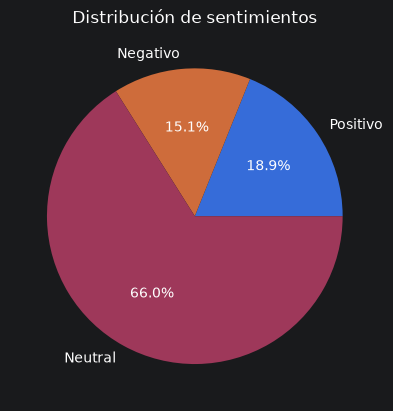

In [8]:
import matplotlib.pyplot as plt

# Datos
clases = ['Positivo', 'Negativo', 'Neutral']
cantidades = [cant_positivos, cant_negativos, cant_neutros]

# Crear gráfico
plt.pie(cantidades, labels=clases, autopct='%1.1f%%')
plt.title('Distribución de sentimientos')
plt.show()

4.1519125683060105
2243
0


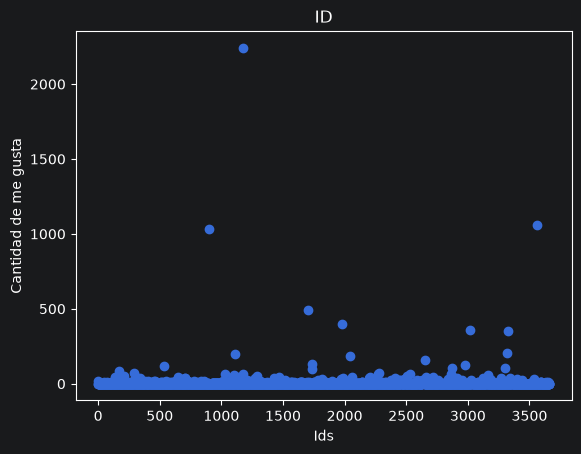

In [9]:
print(df["favorite_count"].mean())
print(df["favorite_count"].max())
print(df["favorite_count"].min())

plt.scatter(range(0,len(df)), df['favorite_count'])

plt.xlabel('Ids')
plt.ylabel('Cantidad de me gusta')
plt.title('ID')

plt.show()

0.9606557377049181
502
0


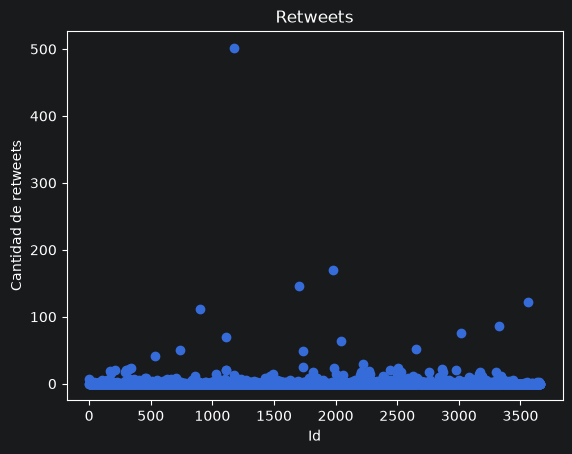

In [10]:
print(df["retweet_count"].mean())
print(df["retweet_count"].max())
print(df["retweet_count"].min())

plt.scatter(range(0,len(df)), df['retweet_count'])

plt.xlabel('Id')
plt.ylabel('Cantidad de retweets')
plt.title('Retweets')

plt.show()

Cantidad de tweets positivo con interaccion:  172
Cantidad de tweets negativos con interaccion:  139
Media de interacciones en positivos:  6.726878612716763
Media de interacciones en negativos:  3.8747731397459164


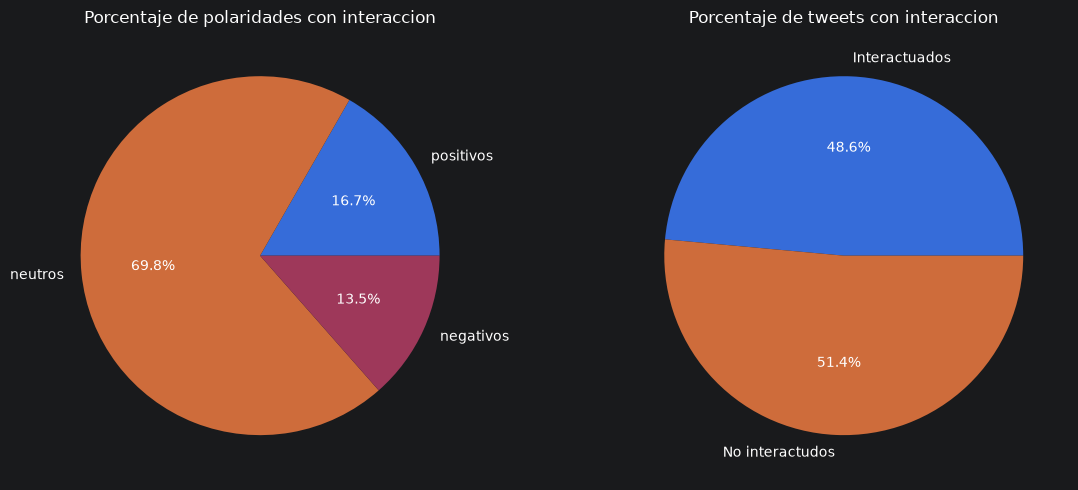

In [11]:
df['tweet_interactions'] = df['favorite_count'] + df['retweet_count']

tweets_con_interaccion = (df['tweet_interactions'] > 0).sum()
tweets_sin_interaccion = (df['tweet_interactions'] == 0).sum()

positivos_con_interaccion = (df[df['polarity'] == 'P']['tweet_interactions'] > 1).sum()
neutros_con_interaccion = (df[df['polarity'] == 'NEU']['tweet_interactions'] > 1).sum()
negativos_con_interaccion = (df[df['polarity'] == 'N']['tweet_interactions'] > 1).sum()
interaccion_positivos_media = df[df['polarity'] == 'P']['tweet_interactions'].mean()
interaccion_negativos_media = df[df['polarity'] == 'N']['tweet_interactions'].mean()

print("Cantidad de tweets positivo con interaccion: ", positivos_con_interaccion)
print("Cantidad de tweets negativos con interaccion: ", negativos_con_interaccion)
print("Media de interacciones en positivos: ", interaccion_positivos_media)
print("Media de interacciones en negativos: ", interaccion_negativos_media)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].pie([positivos_con_interaccion, neutros_con_interaccion, negativos_con_interaccion], labels=["positivos", "neutros", "negativos"], autopct='%1.1f%%')
ax[0].set_title('Porcentaje de polaridades con interaccion')

ax[1].pie([tweets_con_interaccion, tweets_sin_interaccion],
  labels=["Interactuados", "No interactudos"], autopct='%1.1f%%')
ax[1].set_title('Porcentaje de tweets con interaccion')

plt.tight_layout()
plt.show()

In [12]:
 #text
#polarity
#favorite_count
#retweet_count
#user_followers_count
#user_friends_count
#user_favourites_count         TEST (Likes que dio)
#user_statuses_count           TEST (Publicaciones y comentarios suyos)
#user_verified                 TEST
#user_default_profile          TEST (Pagina de perfil default)

import unicodedata

def contar_emojis(texto):
    return sum(1 for caracter in str(texto) if unicodedata.category(caracter) == 'So')

df["length"] = df['text'].apply(lambda texto: len(texto.split()))
df["hashtag_count"] = df['text'].apply(lambda texto: texto.count('#'))
df["mention_count"] = df['text'].apply(lambda texto: texto.count('@'))
df["url_count"] = df['text'].apply(lambda texto: texto.count('http'))
df["punctuation_count"] = df['text'].apply(lambda texto: texto.count('?') + texto.count('!'))
df['emoji_count'] = df['text'].apply(contar_emojis)

# :url: :mencion:

#Campos extra
#Longitud (palabras)
#Cantidad de hashtags
#Cantidad de usuarios mencionados
#Cantidad de emojis
#Cantidad de urls
#Cantidad de signos de exclamacion/interrogacion

In [13]:
df["text"] = df["text"].str.replace(r"http\S+|www\.\S+", "URL", regex=True)
df["text"] = df["text"].str.replace(r"@\w+", "MENCION", regex=True)

df.head()

,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_default_profile,tweet_interactions,length,hashtag_count,mention_count,url_count,punctuation_count,emoji_count
0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,0,28,44,0,0,1,0,0
1,"MENCION Eso es imposible. Y sí, va a generar u...",N,1,0,685,851,169490,128555,0,1,1,41,0,1,0,0,0
2,MENCION Lo disruptivo es que tras años de deci...,NEU,1,0,685,851,169490,128555,0,1,1,39,0,1,0,0,0
3,"MENCION ¿""Prohibición del uso comercial de las...",N,0,0,4877,538,6123,3156,0,0,0,17,0,1,0,1,0
4,MENCION Cómo se está estudiando prohibir chatG...,NEU,0,0,15936,2395,66945,68578,0,0,0,39,0,1,0,1,0


In [14]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["polarity"])
y = df["polarity"]

# 60% para train y 40% para test y validacion
X_train, X_test_val, y_train, y_test_val = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Segunda división: separar test y validación
X_test, X_val, y_test, y_val = train_test_split(
    X_test_val, y_test_val,
    test_size=0.5,
    random_state=42,
    stratify=y_test_val
)

print(len(X_train)/len(df))

0.6


In [15]:
from sklearn.preprocessing import StandardScaler

number_columns = ["favorite_count","retweet_count","user_followers_count", "user_friends_count", "user_favourites_count", "user_statuses_count", "tweet_interactions", "hashtag_count", "mention_count"]

scaler = StandardScaler()

X_train[number_columns] = scaler.fit_transform(X_train[number_columns])

y_train = pd.get_dummies(y_train, columns=["polarity"], dtype=int, drop_first=True)

X_train.head()
y_train.head()

,NEU,P
1468,1,0
3145,1,0
2137,1,0
3883,1,0
2562,1,0


In [16]:
from sklearn.base import BaseEstimator, TransformerMixin
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
import string

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')
stop_words = set(stopwords.words('spanish'))

class TextCleaner(BaseEstimator, TransformerMixin):
    def __init__(self, method=None):
        self.method = method

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        # Inicializamos dentro de transform para evitar errores de multiprocessing
        stop_words = set(stopwords.words('spanish'))
        punctuation = set(string.punctuation)
        stemmer = PorterStemmer()
        lemmatizer = WordNetLemmatizer()

        clean_X = []
        for text in X:
            # 1. Minúsculas y Tokenización
            tokens = nltk.word_tokenize(text.lower())

            # 2. Remover Stopwords y Puntuación
            tokens = [t for t in tokens if t not in stop_words and t not in punctuation]

            # 3. Reducción a raíz (Stemming o Lemmatization)
            if self.method == 'stem':
                tokens = [stemmer.stem(t) for t in tokens]
            elif self.method == 'lemma':
                tokens = [lemmatizer.lemmatize(t) for t in tokens]

            clean_X.append(" ".join(tokens))
        return clean_X

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\matia\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\matia\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\matia\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [17]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

cleaner = TextCleaner("lemma")

vectores = cleaner.transform(df["text"])
vectorizer_BoW = CountVectorizer()
vectorizer_Tfidf = TfidfVectorizer()


matriz_BoW = vectorizer_BoW.fit_transform(vectores)
matriz_Tfidf = vectorizer_Tfidf.fit_transform(vectores)

print(vectorizer_BoW.get_feature_names_out())
print(matriz_BoW.toarray()[0])
#print(vectores_Tfidf.shape)

['00' '000' '003' ... '𝙀𝙣𝙩𝙧𝙚𝙥𝙖𝙧𝙦𝙪𝙚𝙨' '𝙈𝙤𝙣𝙩𝙚𝙨𝙪𝙧' '𝙈𝙤𝙣𝙩𝙞𝙚𝙡']
[0 0 0 ... 0 0 0]


In [18]:
from sentence_transformers import SentenceTransformer # <- Estandar para Embeddings

class EmbeddingTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, model_name='paraphrase-multilingual-MiniLM-L12-v2'):
        self.model_name = model_name
        self.model = None

    def fit(self, X, y=None):
        # Cargamos el modelo aquí para evitar errores de serialización
        if self.model is None:
            self.model = SentenceTransformer(self.model_name)
        return self

    def transform(self, X):
        # Convertimos la lista de textos en una matriz de vectores (Embeddings)
        # Esto implementa implícitamente el "Mean Pooling"
        return self.model.encode(list(X), show_progress_bar=False)

embedding = EmbeddingTransformer()

In [19]:
embedding.fit(df["text"])
text = embedding.transform(df["text"])
print(text.shape)
print(text)

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

C:\Users\matia\PycharmProjects\Tp_tweets\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\matia\.cache\huggingface\hub\models--sentence-transformers--paraphrase-multilingual-MiniLM-L12-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

C:\Users\matia\PycharmProjects\Tp_tweets\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\matia\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/526 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 9.08MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

(3660, 384)
[[ 0.15161385  0.13791269 -0.15399659 ... -0.23173821  0.18059729
   0.07939073]
 [-0.05797388 -0.24207357  0.1003264  ... -0.01575597  0.2149977
  -0.11276339]
 [-0.06540345 -0.17857747  0.19099697 ...  0.08109542  0.40129176
   0.07221729]
 ...
 [-0.26395094 -0.03915968 -0.14702237 ... -0.07476871 -0.2275236
   0.05211054]
 [-0.06131364 -0.00176563  0.1604707  ... -0.01875054 -0.07580694
  -0.18729645]
 [ 0.05583208 -0.19120206 -0.01426136 ...  0.0142399  -0.07063262
   0.05583797]]


In [20]:
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.base import BaseEstimator, TransformerMixin

# Definición del transformador a denso
class DenseTransformer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        if hasattr(X, "toarray"):
            return X.toarray()
        return X

X_train, X_test, y_train, y_test = train_test_split(df['text'], df['polarity'], test_size=0.2, random_state=42)

# El Pipeline combina el vectorizador y el clasificador
pipeline = Pipeline([
    ('cleaner', TextCleaner()), # Nuestro Transformador
    ('vectorizer', CountVectorizer()), # BoW inicial
    ('to_dense', DenseTransformer()),
    ('classifier', GaussianNB())
])

# Parámetros a tunear
param_grid = [
    # Opción 1: Naive Bayes con distintas vectorizaciones y n-gramas
    {
        'cleaner__method': [None, 'stem', 'lemma'],
        'vectorizer': [CountVectorizer(), TfidfVectorizer()],
        'vectorizer__ngram_range': [(1, 1), (1, 2)], # Unigramas vs Bigramas
        'classifier': [GaussianNB()],
        'classifier__var_smoothing': [1e-9, 1e-8, 1e-7, 1e-5, 1e-3]
    },
    # Opción 2: Gaussian Naive Bayes
    {
        'cleaner__method': ['lemma'],
        'vectorizer': [TfidfVectorizer()],
        'classifier': [GaussianNB()],
        'classifier__var_smoothing': [1e-9, 1e-8, 1e-7]
    }
]

# Ejecución del Grid Search optimizando roc-auc
grid_search = GridSearchCV(pipeline, param_grid, cv=2, scoring='roc_auc', n_jobs=1, verbose=1)
grid_search.fit(X_train, y_train)

Fitting 2 folds for each of 63 candidates, totalling 126 fits


C:\Users\matia\PycharmProjects\Tp_tweets\.venv\Lib\site-packages\sklearn\model_selection\_validation.py:960: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "C:\Users\matia\PycharmProjects\Tp_tweets\.venv\Lib\site-packages\sklearn\model_selection\_validation.py", line 949, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
  File "C:\Users\matia\PycharmProjects\Tp_tweets\.venv\Lib\site-packages\sklearn\utils\validation.py", line 80, in inner_f
    return f(*args, **kwargs)
  File "C:\Users\matia\PycharmProjects\Tp_tweets\.venv\Lib\site-packages\sklearn\metrics\_scorer.py", line 328, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **kwargs)
           ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\matia\PycharmProjects\Tp_tweets\.venv\Lib\site-packages\sklearn\metrics\_score

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...aussianNB())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'classifier': [GaussianNB()], 'classifier__var_smoothing': [1e-09, 1e-08, ...], 'cleaner__method': [None, 'stem', ...], 'vectorizer': [CountVectorizer(), TfidfVectorizer()], ...}, {'classifier': [GaussianNB()], 'classifier__var_smoothing': [1e-09, 1e-08, ...], 'cleaner__method': ['lemma'], 'vectorizer': [TfidfVectorizer()]}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",2
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_param

In [21]:
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import classification_report, roc_auc_score

X = df["text"]
y = df["polarity"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

pipeline = Pipeline([
    ("cleaner", TextCleaner()),
    ("vectorizer", CountVectorizer()),
    ("to_dense", DenseTransformer()),
    ("classifier", GaussianNB()),
])

param_grid = [
    {
        "cleaner__method": [None, "stem"],
        "vectorizer": [TfidfVectorizer()],
        "vectorizer__ngram_range": [(1, 1), (1, 2)],
        "vectorizer__min_df": [2],
        "vectorizer__max_df": [0.5, 0.8, 1.0],
        "vectorizer__sublinear_tf": [True, False],
        "classifier__var_smoothing": [1e-9, 1e-8, 1e-7, 1e-5, 1e-3],
    },
    {
        "vectorizer": [CountVectorizer()],
        "vectorizer__ngram_range": [(1, 1), (1, 2)],
        "vectorizer__min_df": [2],
        "vectorizer__max_df": [0.5, 0.8, 1.0],
        "cleaner__method": [None, "stem"],
        "classifier__var_smoothing": [1e-9, 1e-8, 1e-7, 1e-5, 1e-3],
    },
]

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=3,
    scoring={
        "f1_macro": "f1_macro",
        "roc_auc_ovr": "roc_auc_ovr",
    },
    refit="roc_auc_ovr",
    n_jobs=1,
    verbose=1,
)

grid_search.fit(X_train, y_train)

idx = grid_search.best_index_

print("Mejores parámetros:", grid_search.best_params_)

print("Mejor F1 macro (validación cruzada):", grid_search.cv_results_["mean_test_f1_macro"][idx])
print("Mejor ROC-AUC OvR:", grid_search.best_score_)


proba = grid_search.predict_proba(X_test)
print("ROC-AUC test (TF-IDF):", roc_auc_score(y_test, proba, multi_class="ovr"))
print(classification_report(y_test, grid_search.predict(X_test)))

Fitting 3 folds for each of 180 candidates, totalling 540 fits
Mejores parámetros: {'classifier__var_smoothing': 0.001, 'cleaner__method': 'stem', 'vectorizer': CountVectorizer(), 'vectorizer__max_df': 0.5, 'vectorizer__min_df': 2, 'vectorizer__ngram_range': (1, 2)}
Mejor F1 macro (validación cruzada): 0.44556175611000676
Mejor ROC-AUC OvR: 0.7140944416424816
ROC-AUC test (TF-IDF): 0.7159769165167263
              precision    recall  f1-score   support

           N       0.27      0.81      0.41       110
         NEU       0.78      0.23      0.35       484
           P       0.37      0.70      0.48       138

    accuracy                           0.40       732
   macro avg       0.47      0.58      0.41       732
weighted avg       0.63      0.40      0.38       732



In [25]:
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.preprocessing import LabelEncoder

# 0. Generar los embeddings de entrenamiento y prueba
embedding = EmbeddingTransformer()
emb_train = embedding.fit_transform(X_train)
emb_test = embedding.transform(X_test)

# 1. Encoding de etiquetas
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

# 2. Pipeline: PCA + GaussianNB
pipe = Pipeline([
    ('pca', PCA(n_components=30)),
    ('gnb', GaussianNB())
])

param_grid_emb = {
    "gnb__var_smoothing": [1e-9, 1e-8, 1e-7, 1e-5, 1e-3, 1e-1],
}

scoring = {
    "f1_macro": "f1_macro",
    "roc_auc_ovr": "roc_auc_ovr"
}

grid_emb = GridSearchCV(
    pipe,
    param_grid_emb,
    cv=3,
    scoring=scoring,
    refit="roc_auc_ovr",
    n_jobs=1,
    verbose=1,
)

grid_emb.fit(emb_train, y_train_encoded)

idx = grid_emb.best_index_
print("Mejores parámetros:", grid_emb.best_params_)
print("F1 macro (CV):", grid_emb.cv_results_["mean_test_f1_macro"][idx])
print("ROC-AUC (CV):", grid_emb.best_score_)

# 3. Evaluación
proba_emb = grid_emb.predict_proba(emb_test)
auc_score = roc_auc_score(y_test_encoded, proba_emb, multi_class="ovr")

print("ROC-AUC test (embeddings):", auc_score)
print(classification_report(y_test_encoded, grid_emb.predict(emb_test), target_names=le.classes_))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Mejores parámetros: {'gnb__var_smoothing': 0.1}
F1 macro (CV): 0.5086577729882732
ROC-AUC (CV): 0.818439893575659
ROC-AUC test (embeddings): 0.816184149524863
              precision    recall  f1-score   support

           N       0.55      0.29      0.38       110
         NEU       0.71      0.94      0.81       484
           P       0.86      0.23      0.37       138

    accuracy                           0.71       732
   macro avg       0.71      0.49      0.52       732
weighted avg       0.72      0.71      0.66       732



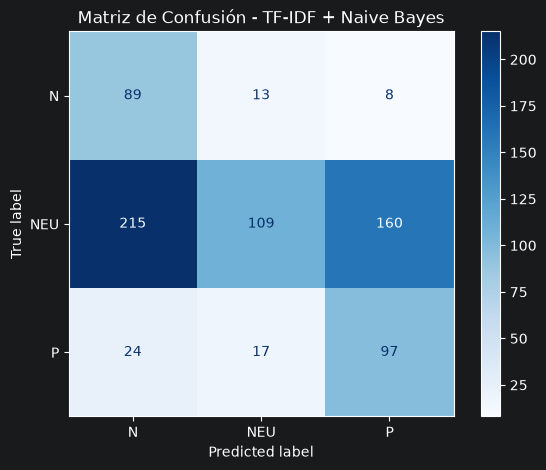

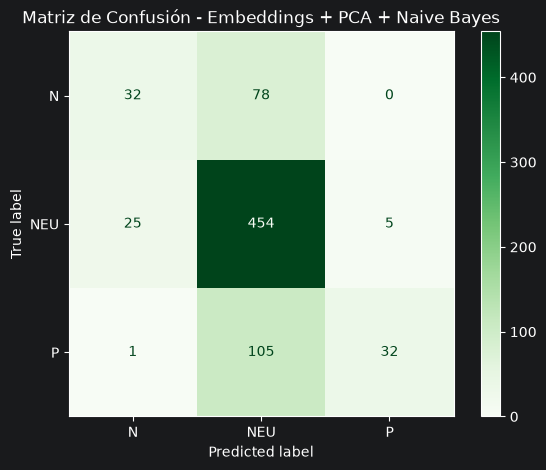

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# --- Matriz de Confusión para Modelo TF-IDF (GridSearchCV) ---
y_pred_tfidf = grid_search.predict(X_test)

fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tfidf,
    display_labels=grid_search.classes_,
    cmap=plt.cm.Blues,
    ax=ax
)
ax.set_title("Matriz de Confusión - TF-IDF + Naive Bayes")
plt.grid(False)
plt.show()

# --- Matriz de Confusión para Modelo Embeddings + PCA ---
y_pred_emb = grid_emb.predict(emb_test)

fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_encoded,
    y_pred_emb,
    display_labels=le.classes_,
    cmap=plt.cm.Greens,
    ax=ax
)
ax.set_title("Matriz de Confusión - Embeddings + PCA + Naive Bayes")
plt.grid(False)
plt.show()

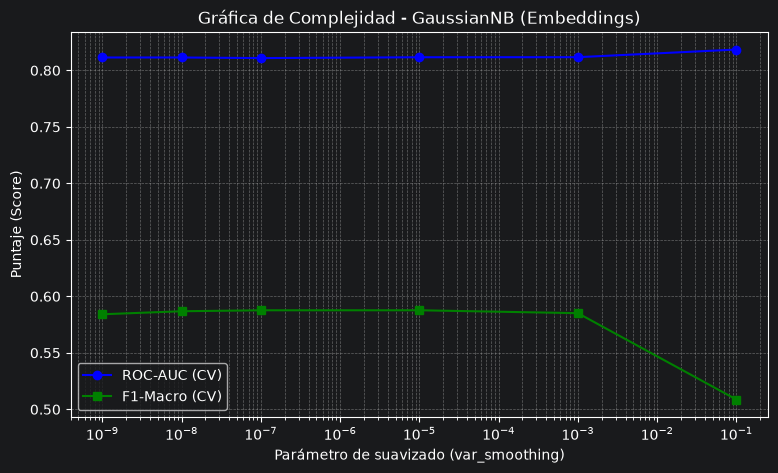

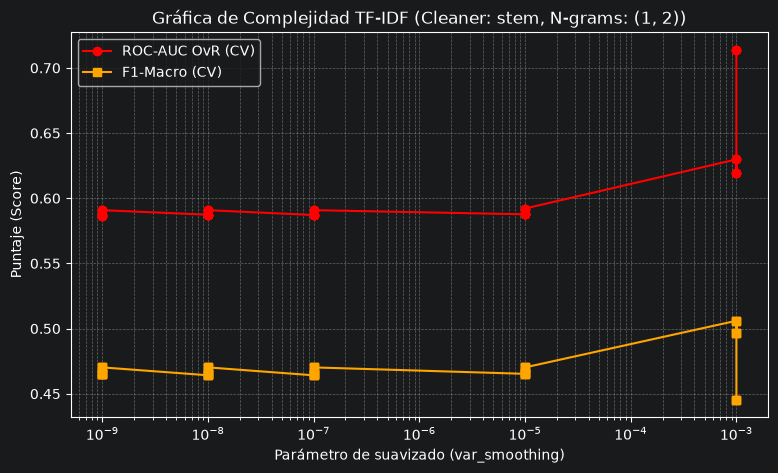

In [27]:
# Embeddings

import numpy as np
import matplotlib.pyplot as plt

# Extraemos las métricas del grid de embeddings
var_smoothing_vals = [p['gnb__var_smoothing'] for p in grid_emb.cv_results_['params']]
scores_auc = grid_emb.cv_results_['mean_test_roc_auc_ovr']
scores_f1 = grid_emb.cv_results_['mean_test_f1_macro']

plt.figure(figsize=(9, 5))
plt.plot(var_smoothing_vals, scores_auc, marker='o', label='ROC-AUC (CV)', color='b')
plt.plot(var_smoothing_vals, scores_f1, marker='s', label='F1-Macro (CV)', color='g')

plt.xscale('log')  # Escala logarítmica para ver claramente los valores de var_smoothing
plt.xlabel('Parámetro de suavizado (var_smoothing)')
plt.ylabel('Puntaje (Score)')
plt.title('Gráfica de Complejidad - GaussianNB (Embeddings)')
plt.legend()
plt.grid(True, which="both", ls="--")
plt.show()


# TF-IDF
import pandas as pd

# Convertimos los resultados de GridSearchCV a DataFrame
results_df = pd.DataFrame(grid_search.cv_results_)

# Filtramos por los mejores parámetros de limpieza y vectorización encontrados
best_cleaner = grid_search.best_params_['cleaner__method']
best_ngram = grid_search.best_params_['vectorizer__ngram_range']

subset = results_df[
    (results_df['param_cleaner__method'] == best_cleaner) &
    (results_df['param_vectorizer__ngram_range'] == best_ngram)
]

# Ordenamos por var_smoothing
subset = subset.sort_values(by='param_classifier__var_smoothing')

# Graficamos
plt.figure(figsize=(9, 5))
plt.plot(
    subset['param_classifier__var_smoothing'],
    subset['mean_test_roc_auc_ovr'],
    marker='o',
    color='r',
    label='ROC-AUC OvR (CV)'
)
plt.plot(
    subset['param_classifier__var_smoothing'],
    subset['mean_test_f1_macro'],
    marker='s',
    color='orange',
    label='F1-Macro (CV)'
)

plt.xscale('log')
plt.xlabel('Parámetro de suavizado (var_smoothing)')
plt.ylabel('Puntaje (Score)')
plt.title(f'Gráfica de Complejidad TF-IDF (Cleaner: {best_cleaner}, N-grams: {best_ngram})')
plt.legend()
plt.grid(True, which="both", ls="--")
plt.show()